# Employee Attrition Prediction

Predicting whether an employee will leave the company from job, compensation, and satisfaction data using classification models.

**Dataset:** `data/WA_Fn-UseC_-HR-Employee-Attrition.csv` — IBM HR Analytics Employee Attrition & Performance (a fictional dataset created by IBM data scientists, published on [Kaggle](https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset)). 1,470 employees, 35 columns.

**Goal:** Train a classification model to predict `Attrition` (`Yes` = left the company) from the other features, and evaluate it on a held-out test set.

## Contents
1. [Load & Inspect Data](#1.-Load-&-Inspect-Data)
2. [Exploratory Data Analysis](#2.-Exploratory-Data-Analysis)
3. [Data Cleaning](#3.-Data-Cleaning)
4. [Data Leakage Check](#4.-Data-Leakage-Check)
5. [Feature Engineering](#5.-Feature-Engineering)
6. [Train / Test Split](#6.-Train-/-Test-Split)
7. [Model Comparison](#7.-Model-Comparison)
8. [Final Model Evaluation](#8.-Final-Model-Evaluation)
9. [Feature Importance](#9.-Feature-Importance)
10. [Conclusion](#10.-Conclusion)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split, cross_val_score, cross_val_predict,
    StratifiedKFold, RepeatedStratifiedKFold,
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    roc_auc_score, average_precision_score, accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix, classification_report,
    roc_curve, precision_recall_curve, ConfusionMatrixDisplay,
)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
RANDOM_STATE = 42

## 1. Load & Inspect Data

In [2]:
df = pd.read_csv("data/WA_Fn-UseC_-HR-Employee-Attrition.csv")
print(df.shape)
df.head()

(1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.923810,9.135373,18.0,30.00,36.0,43.00,60.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.912925,1.024165,1.0,2.00,3.0,4.00,5.0
EmployeeCount,1470.0,1.000000,0.000000,1.0,1.00,1.0,1.00,1.0
EmployeeNumber,1470.0,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0
EnvironmentSatisfaction,1470.0,2.721769,1.093082,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.729932,0.711561,1.0,2.00,3.0,3.00,4.0
JobLevel,1470.0,2.063946,1.106940,1.0,1.00,2.0,3.00,5.0


In [5]:
# Missing values & duplicates
print("Missing values :", df.isna().sum().sum())
print("Duplicate rows :", df.duplicated().sum())

Missing values : 0
Duplicate rows : 0


## 2. Exploratory Data Analysis

### 2.1 Attrition distribution
Only a minority of employees left, so the target is **imbalanced**. This matters for modeling in the same way price skew mattered for the house-price project: a model that always predicts "stays" would already be right most of the time, so plain accuracy is misleading. We use a stratified split, class weighting where it helps, and metrics that focus on the minority class (ROC AUC, PR AUC, recall, precision, F1).

           count  percent
Attrition                
No          1233    83.88
Yes          237    16.12


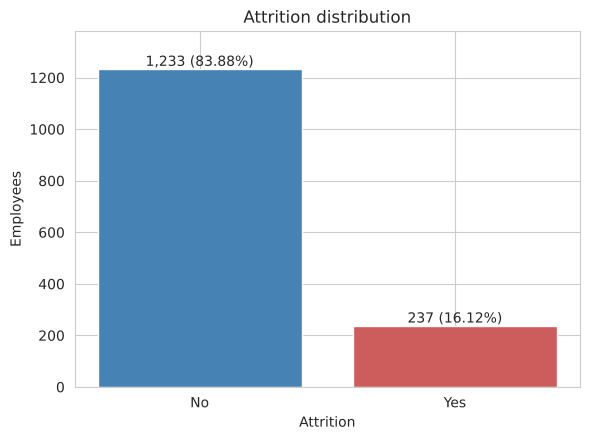

In [6]:
attr_counts = df["Attrition"].value_counts().reindex(["No", "Yes"])
attr_pct = (attr_counts / len(df) * 100).round(2)
print(pd.DataFrame({"count": attr_counts, "percent": attr_pct}))

fig, ax = plt.subplots(figsize=(6, 4.5))
bars = ax.bar(attr_counts.index, attr_counts.values, color=["steelblue", "indianred"])
ax.bar_label(bars, labels=[f"{v:,} ({p}%)" for v, p in zip(attr_counts.values, attr_pct.values)])
ax.set_title("Attrition distribution")
ax.set_xlabel("Attrition")
ax.set_ylabel("Employees")
ax.set_ylim(0, attr_counts.max() * 1.12)
plt.tight_layout()
plt.show()

Baseline to beat: a model that predicts "No" for everyone has an accuracy equal to the "No" share above, but catches **zero** leavers.

### 2.2 Attrition rate by categorical drivers

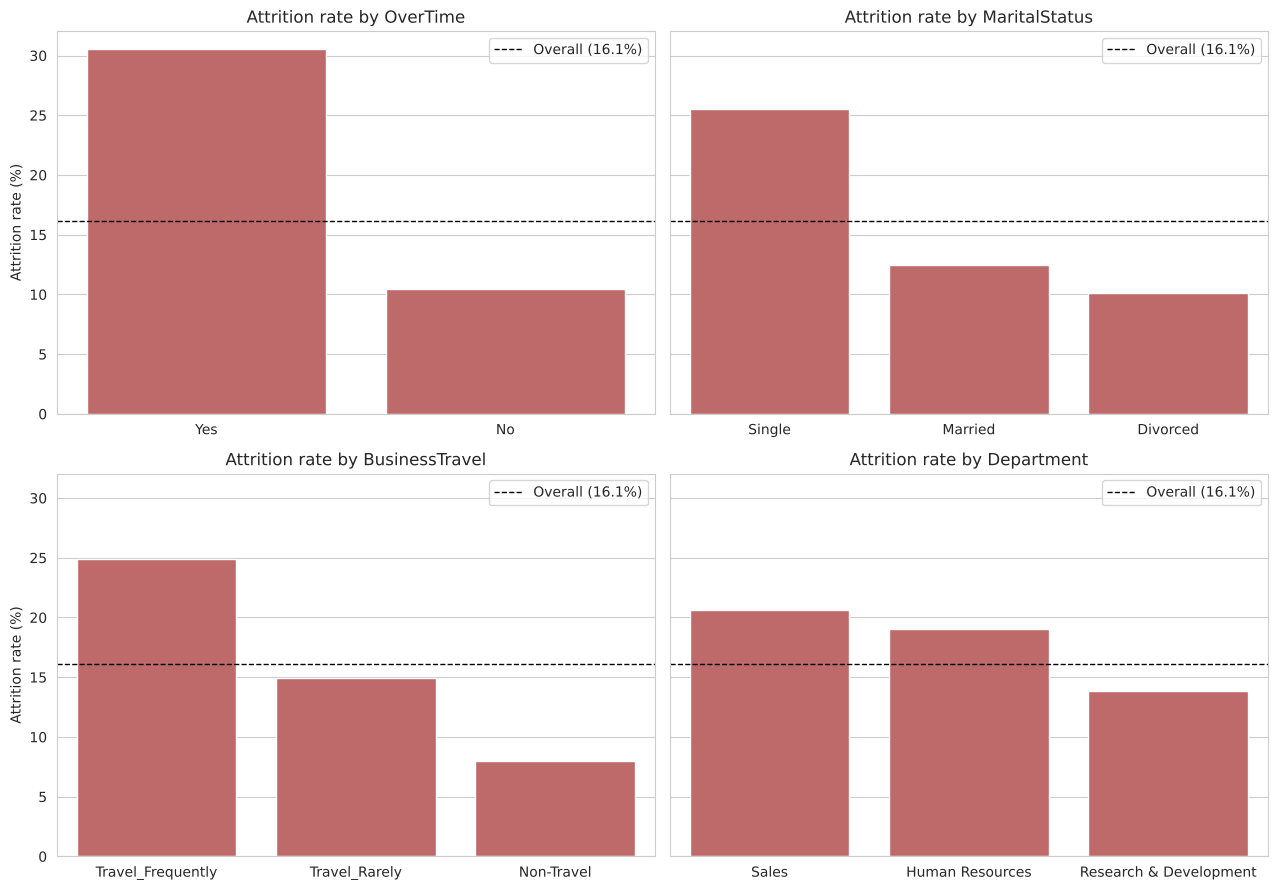

In [7]:
cat_drivers = ["OverTime", "MaritalStatus", "BusinessTravel", "Department"]
overall_rate = (df["Attrition"] == "Yes").mean() * 100

fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharey=True)
for ax, col in zip(axes.ravel(), cat_drivers):
    rate = (
        df.groupby(col)["Attrition"]
        .apply(lambda s: (s == "Yes").mean() * 100)
        .sort_values(ascending=False)
    )
    sns.barplot(x=rate.index, y=rate.values, color="indianred", ax=ax)
    ax.axhline(overall_rate, color="black", linestyle="--", linewidth=1, label=f"Overall ({overall_rate:.1f}%)")
    ax.set_title(f"Attrition rate by {col}")
    ax.set_xlabel("")
    ax.set_ylabel("Attrition rate (%)")
    ax.legend()
plt.tight_layout()
plt.show()

### 2.3 Numeric drivers: leavers vs. stayers

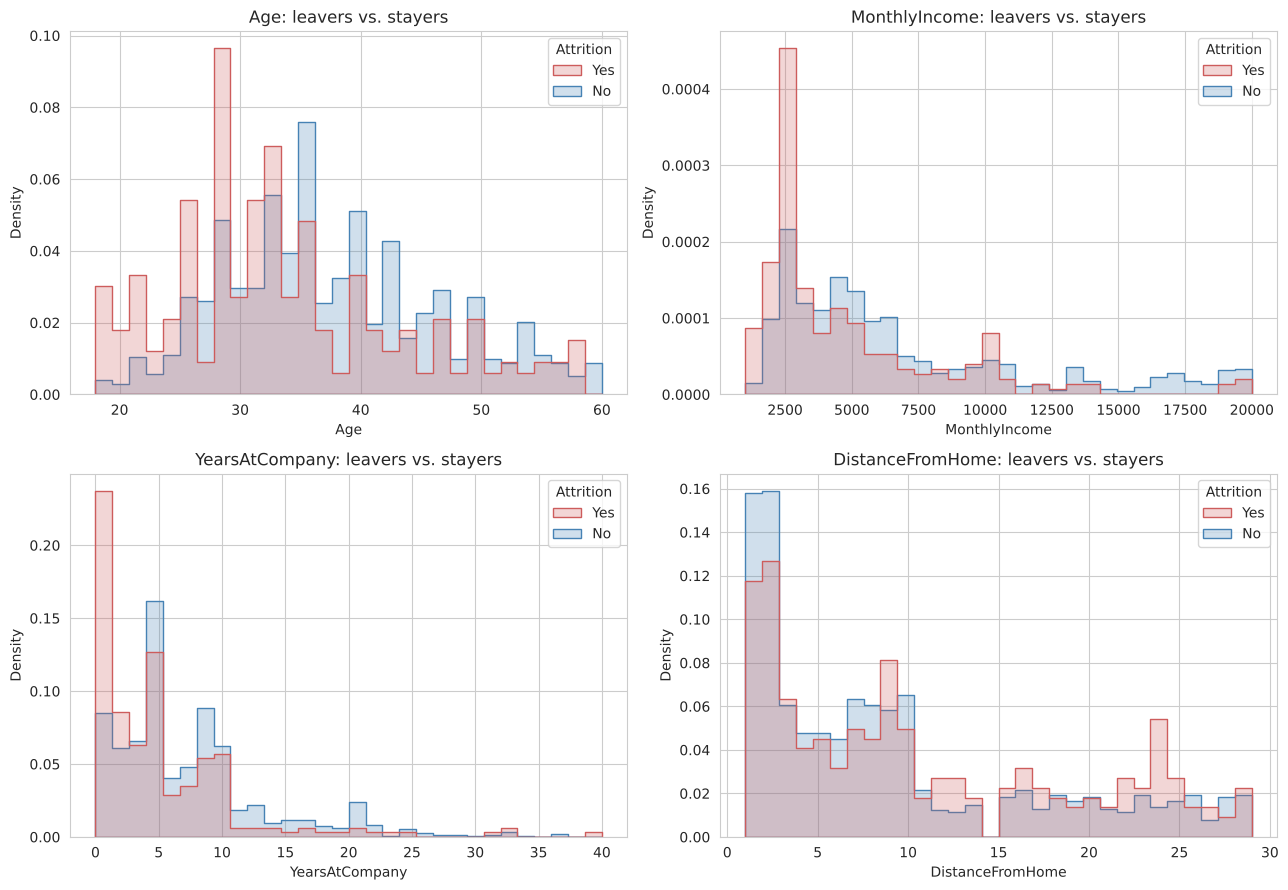

In [8]:
num_drivers = ["Age", "MonthlyIncome", "YearsAtCompany", "DistanceFromHome"]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, col in zip(axes.ravel(), num_drivers):
    sns.histplot(
        data=df, x=col, hue="Attrition", stat="density", common_norm=False,
        bins=30, element="step", palette={"No": "steelblue", "Yes": "indianred"}, ax=ax,
    )
    ax.set_title(f"{col}: leavers vs. stayers")
plt.tight_layout()
plt.show()

### 2.4 Correlation heatmap (numeric features)

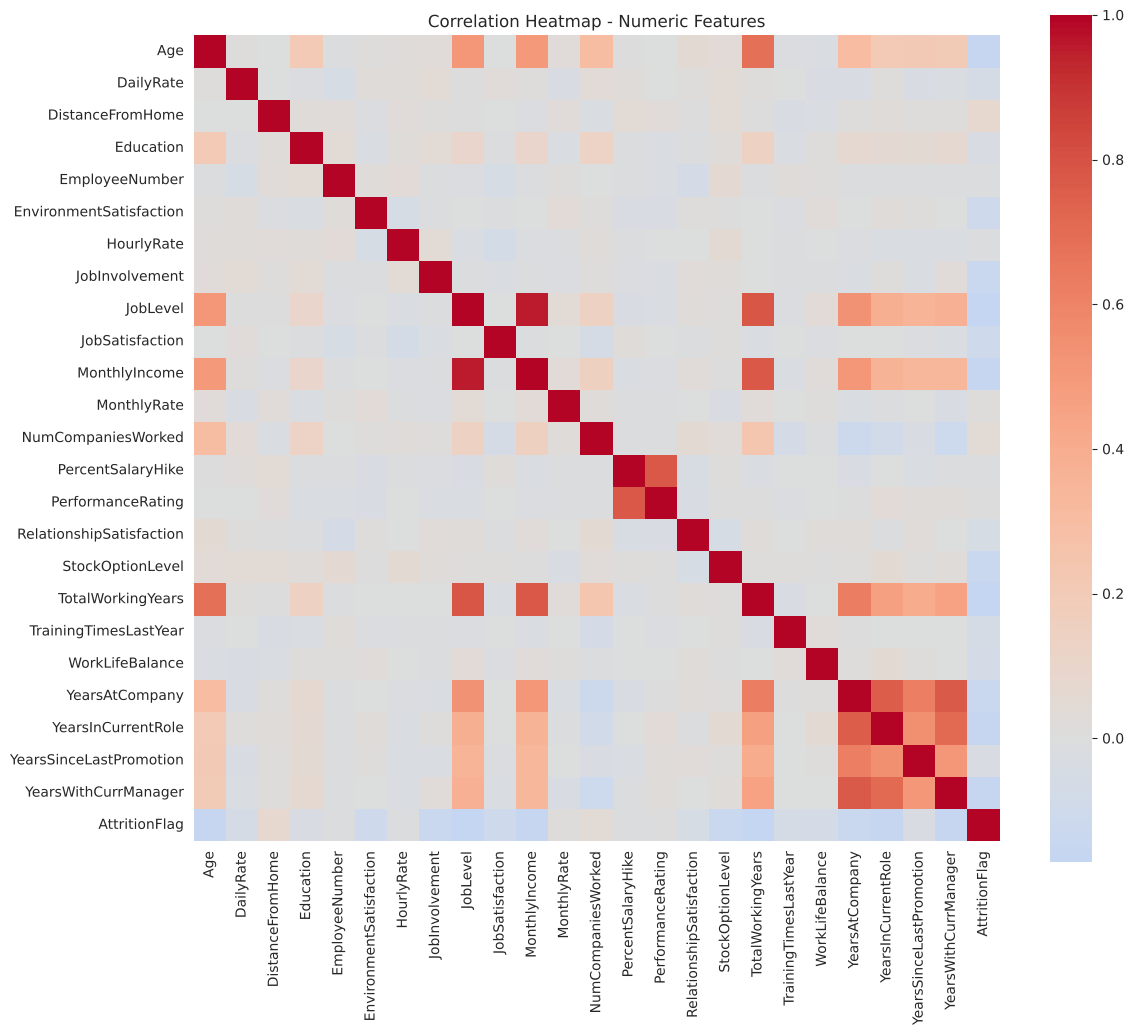

Strongest correlations with attrition:
TotalWorkingYears      -0.171
JobLevel               -0.169
YearsInCurrentRole     -0.161
MonthlyIncome          -0.160
Age                    -0.159
YearsWithCurrManager   -0.156
StockOptionLevel       -0.137
YearsAtCompany         -0.134
Name: AttritionFlag, dtype: float64


In [9]:
numeric_df = df.assign(AttritionFlag=(df["Attrition"] == "Yes").astype(int)).select_dtypes(include=[np.number])
numeric_df = numeric_df.loc[:, numeric_df.nunique() > 1]   # constant columns have no correlation
corr = numeric_df.corr()

plt.figure(figsize=(13, 11))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False, square=True)
plt.title("Correlation Heatmap - Numeric Features")
plt.show()

print("Strongest correlations with attrition:")
print(corr["AttritionFlag"].drop("AttritionFlag").sort_values(key=abs, ascending=False).head(8).round(3))

### 2.5 Attrition rate by job role

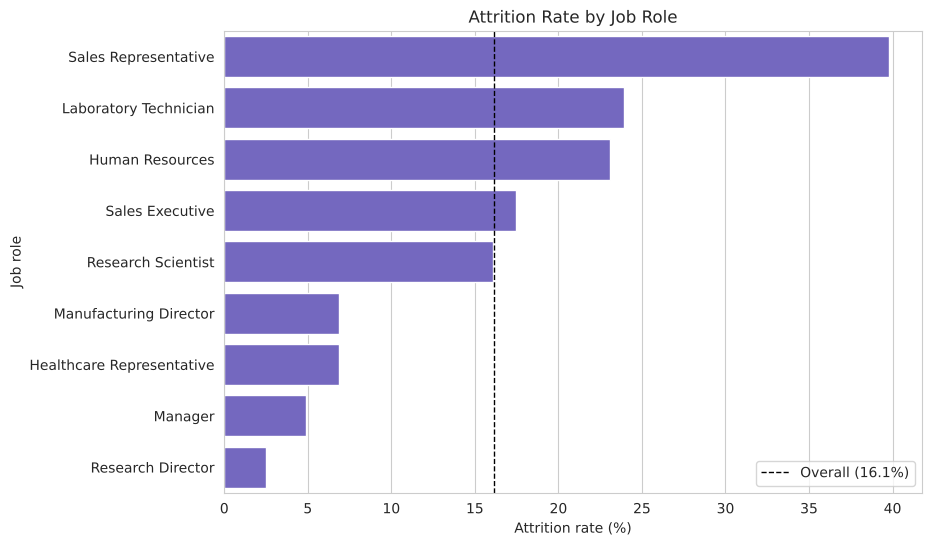

,Employees,AttritionRate
JobRole,,
Sales Representative,83,39.8
Laboratory Technician,259,23.9
Human Resources,52,23.1
Sales Executive,326,17.5
Research Scientist,292,16.1
Manufacturing Director,145,6.9
Healthcare Representative,131,6.9
Manager,102,4.9
Research Director,80,2.5


In [10]:
role_stats = (
    df.groupby("JobRole")["Attrition"]
    .agg(Employees="size", AttritionRate=lambda s: (s == "Yes").mean() * 100)
    .sort_values("AttritionRate", ascending=False)
)

plt.figure(figsize=(9, 6))
ax = sns.barplot(x=role_stats["AttritionRate"], y=role_stats.index, color="slateblue")
ax.axvline(overall_rate, color="black", linestyle="--", linewidth=1, label=f"Overall ({overall_rate:.1f}%)")
plt.title("Attrition Rate by Job Role")
plt.xlabel("Attrition rate (%)")
plt.ylabel("Job role")
plt.legend()
plt.show()

role_stats.round(1)

## 3. Data Cleaning

The data has no missing values and no duplicate rows. Cleaning is therefore about removing columns that carry no information:

- `EmployeeCount`, `Over18`, `StandardHours` — contain a single value for every employee, so they cannot help a model.
- The target `Attrition` is encoded as `AttritionFlag` (1 = left, 0 = stayed).

In [11]:
constant_cols = [c for c in df.columns if df[c].nunique() == 1]
print("Constant columns:", constant_cols)

df = df.drop(columns=constant_cols)
df["AttritionFlag"] = (df["Attrition"] == "Yes").astype(int)
print("Remaining shape:", df.shape)

Constant columns: ['EmployeeCount', 'Over18', 'StandardHours']
Remaining shape: (1470, 33)


## 4. Data Leakage Check

In the house-price project, `price_per_sqft` was derived from the target and had to be removed. Here we run the equivalent checks:

1. **Identifier check:** `EmployeeNumber` is unique per row — it should carry no real signal.
2. **Single-feature scan:** fit a tiny decision tree (depth 3) on each feature alone and cross-validate its ROC AUC. A feature that is secretly derived from the target would score close to 1.0 on its own.
3. **Logical consistency:** tenure columns should never exceed total time at the company or in work.

EmployeeNumber is unique per row: True
EmployeeNumber single-feature AUC: 0.499  (0.5 = no signal)
Highest single-feature AUC       : JobLevel = 0.661


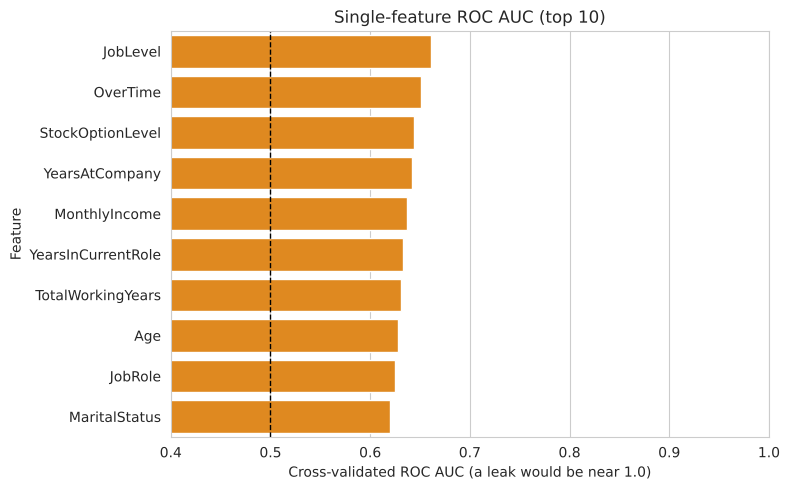

In [12]:
def single_feature_auc(frame, target, cols):
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    scores = {}
    for c in cols:
        Xc = frame[[c]] if pd.api.types.is_numeric_dtype(frame[c]) else pd.get_dummies(frame[[c]]).astype(float)
        tree = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)
        scores[c] = cross_val_score(tree, Xc, target, cv=cv, scoring="roc_auc").mean()
    return pd.Series(scores).sort_values(ascending=False)

feature_cols = df.columns.drop(["Attrition", "AttritionFlag"])
scan = single_feature_auc(df, df["AttritionFlag"], feature_cols)

print(f"EmployeeNumber is unique per row: {df['EmployeeNumber'].is_unique}")
print(f"EmployeeNumber single-feature AUC: {scan['EmployeeNumber']:.3f}  (0.5 = no signal)")
print(f"Highest single-feature AUC       : {scan.index[0]} = {scan.iloc[0]:.3f}")

top10 = scan.head(10)
plt.figure(figsize=(8, 5))
sns.barplot(x=top10.values, y=top10.index, color="darkorange")
plt.axvline(0.5, color="black", linestyle="--", linewidth=1)
plt.xlim(0.4, 1.0)
plt.title("Single-feature ROC AUC (top 10)")
plt.ylabel("Feature")
plt.xlabel("Cross-validated ROC AUC (a leak would be near 1.0)")
plt.tight_layout()
plt.show()

In [13]:
checks = {
    "YearsAtCompany > TotalWorkingYears": (df["YearsAtCompany"] > df["TotalWorkingYears"]).sum(),
    "YearsInCurrentRole > YearsAtCompany": (df["YearsInCurrentRole"] > df["YearsAtCompany"]).sum(),
    "YearsWithCurrManager > YearsAtCompany": (df["YearsWithCurrManager"] > df["YearsAtCompany"]).sum(),
    "YearsSinceLastPromotion > YearsAtCompany": (df["YearsSinceLastPromotion"] > df["YearsAtCompany"]).sum(),
}
pd.Series(checks, name="violating rows")

YearsAtCompany > TotalWorkingYears          0
YearsInCurrentRole > YearsAtCompany         0
YearsWithCurrManager > YearsAtCompany       0
YearsSinceLastPromotion > YearsAtCompany    0
Name: violating rows, dtype: int64

**Conclusion:** no leakage found.

- The strongest single feature (`JobLevel`) reaches only about 0.66 ROC AUC on its own — far from the ~1.0 that a column derived from the target would score.
- All four tenure consistency checks report 0 violating rows.
- `EmployeeNumber` scores about 0.50 (pure chance): it is an identifier with no predictive value, so it is dropped below.

One caveat no check can catch: the dataset is a single snapshot and does not say when each value was measured relative to an employee's departure, so tenure-style features (`YearsAtCompany`, `YearsInCurrentRole`, ...) may partly reflect *when* someone left. This cannot be verified from the data, so treat the results as a demonstration of the method rather than a validated production tool.

In [14]:
df = df.drop(columns=["EmployeeNumber"])
print("Remaining shape:", df.shape)

Remaining shape: (1470, 32)


## 5. Feature Engineering

Four candidate features built from existing columns:

- `TenureRatio` — share of the working life spent at this company (`YearsAtCompany / (TotalWorkingYears + 1)`)
- `AvgYearsPerCompany` — job-hopping indicator (`TotalWorkingYears / (NumCompaniesWorked + 1)`)
- `IncomePerJobLevel` — pay relative to seniority (`MonthlyIncome / JobLevel`)
- `SatisfactionScore` — mean of the four satisfaction / work-life ratings

Categorical columns (`OverTime`, `JobRole`, `MaritalStatus`, ...) are one-hot encoded inside the modeling pipeline. The integer-coded ratings (`JobSatisfaction`, `JobLevel`, ...) are ordinal, so they are kept as numbers.

Whether the engineered features actually help is tested in section 7.1 using training data only.

In [15]:
def add_features(data):
    data = data.copy()
    data["TenureRatio"] = data["YearsAtCompany"] / (data["TotalWorkingYears"] + 1)
    data["AvgYearsPerCompany"] = data["TotalWorkingYears"] / (data["NumCompaniesWorked"] + 1)
    data["IncomePerJobLevel"] = data["MonthlyIncome"] / data["JobLevel"]
    data["SatisfactionScore"] = data[
        ["EnvironmentSatisfaction", "JobSatisfaction", "RelationshipSatisfaction", "WorkLifeBalance"]
    ].mean(axis=1)
    return data


y = df["AttritionFlag"]
X_base = df.drop(columns=["Attrition", "AttritionFlag"])
base_cols = X_base.columns.tolist()
X = add_features(X_base)

print("Original features  :", len(base_cols))
print("With engineered    :", X.shape[1])
print("Engineered features:", [c for c in X.columns if c not in base_cols])

Original features  : 30
With engineered    : 34
Engineered features: ['TenureRatio', 'AvgYearsPerCompany', 'IncomePerJobLevel', 'SatisfactionScore']


## 6. Train / Test Split

The split is **stratified** so the training and test sets both keep the same share of leavers.

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(f"Train: {X_train.shape[0]} rows | Test: {X_test.shape[0]} rows")
print(f"Leavers in train: {y_train.sum()} ({y_train.mean():.1%}) | in test: {y_test.sum()} ({y_test.mean():.1%})")

Train: 1176 rows | Test: 294 rows
Leavers in train: 190 (16.2%) | in test: 47 (16.0%)


## 7. Model Comparison

We build a `scikit-learn` **Pipeline** that one-hot encodes the categorical columns (and standardizes the numeric ones for Logistic Regression), so preprocessing never leaks information from the test set. We compare:

- Baseline — always predicts the majority class (the score any real model must beat)
- Logistic Regression (`class_weight="balanced"`)
- Random Forest
- Random Forest (`class_weight="balanced_subsample"`)
- Gradient Boosting

The two Random Forests differ only in class weighting, mirroring the "raw vs. log target" comparison in the house-price project.

Each model is scored with 5-fold **stratified** cross-validation on the training set (ROC AUC), then evaluated once on the held-out test set. The final model is picked from the **cross-validation** score, not the test score, so the test set stays an unbiased final check.

In [17]:
def build_pipeline(model, scale=False, columns=None):
    cols = columns if columns is not None else X_train.columns.tolist()
    cat_cols = [c for c in cols if not pd.api.types.is_numeric_dtype(X_train[c])]
    num_cols = [c for c in cols if c not in cat_cols]

    transformers = [("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), cat_cols)]
    if scale:
        transformers.append(("num", StandardScaler(), num_cols))
    preprocessor = ColumnTransformer(transformers=transformers, remainder="passthrough")
    return Pipeline(steps=[("preprocess", preprocessor), ("model", model)])

### 7.1 Do the engineered features help?
Compared with repeated 5-fold CV (3 repeats) on the training set only.

In [18]:
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)

ablation_models = {
    "Logistic Regression": lambda cols: build_pipeline(
        LogisticRegression(max_iter=2000, class_weight="balanced"), scale=True, columns=cols),
    "Random Forest": lambda cols: build_pipeline(
        RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1), columns=cols),
}

rows = []
for name, make in ablation_models.items():
    raw = cross_val_score(make(base_cols), X_train[base_cols], y_train, cv=rcv, scoring="roc_auc", n_jobs=-1)
    eng = cross_val_score(make(X_train.columns.tolist()), X_train, y_train, cv=rcv, scoring="roc_auc", n_jobs=-1)
    rows.append({
        "Model": name,
        "CV AUC (original features)": raw.mean(),
        "CV AUC (+ engineered)": eng.mean(),
        "Difference": eng.mean() - raw.mean(),
        "Fold std": eng.std(),
    })

ablation_df = pd.DataFrame(rows).set_index("Model").round(4)
ablation_df

,CV AUC (original features),CV AUC (+ engineered),Difference,Fold std
Model,,,,
Logistic Regression,0.8255,0.8276,0.0022,0.0273
Random Forest,0.7974,0.7993,0.0020,0.0271


The engineered features add roughly **+0.002 ROC AUC** for both models — well inside the fold-to-fold noise (std ≈ 0.03). They neither help nor hurt measurably. They are kept because they are cheap, easy to explain (e.g. `SatisfactionScore`) and cross-validation did not penalize them, but the honest reading is that the original columns already hold nearly all of the usable signal.

### 7.2 Compare models

In [19]:
models = {
    "Baseline (majority class)": build_pipeline(DummyClassifier(strategy="prior")),
    "Logistic Regression (balanced)": build_pipeline(
        LogisticRegression(max_iter=2000, class_weight="balanced"), scale=True),
    "Random Forest": build_pipeline(
        RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)),
    "Random Forest (balanced)": build_pipeline(
        RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                               random_state=RANDOM_STATE, n_jobs=-1)),
    "Gradient Boosting": build_pipeline(GradientBoostingClassifier(random_state=RANDOM_STATE)),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

results = []
for name, pipe in models.items():
    cv_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    pipe.fit(X_train, y_train)
    y_proba = pipe.predict_proba(X_test)[:, 1]
    y_pred = pipe.predict(X_test)

    results.append({
        "Model": name,
        "CV ROC AUC (mean)": cv_scores.mean(),
        "CV ROC AUC (std)": cv_scores.std(),
        "Test ROC AUC": roc_auc_score(y_test, y_proba),
        "Test PR AUC": average_precision_score(y_test, y_proba),
        "Test Accuracy": accuracy_score(y_test, y_pred),
        "Test Precision": precision_score(y_test, y_pred, zero_division=0),
        "Test Recall": recall_score(y_test, y_pred),
        "Test F1": f1_score(y_test, y_pred),
    })

results_df = pd.DataFrame(results).set_index("Model").round(3)
results_df

,CV ROC AUC (mean),CV ROC AUC (std),Test ROC AUC,Test PR AUC,Test Accuracy,Test Precision,Test Recall,Test F1
Model,,,,,,,,
Baseline (majority class),0.500,0.000,0.500,0.160,0.840,0.000,0.000,0.000
Logistic Regression (balanced),0.830,0.027,0.799,0.553,0.735,0.322,0.596,0.418
Random Forest,0.808,0.032,0.778,0.417,0.837,0.444,0.085,0.143
Random Forest (balanced),0.813,0.027,0.769,0.388,0.844,0.571,0.085,0.148
Gradient Boosting,0.808,0.022,0.797,0.491,0.854,0.625,0.213,0.317


**Reading the table:**

- **Logistic Regression (balanced)** has the best cross-validated ROC AUC (0.830) and the best test PR AUC. The tree models are close (≈ 0.80–0.81 CV AUC) but not better. The gaps between the real models are small compared with the fold-to-fold std (≈ 0.03), so they are roughly comparable — Logistic Regression is simply the simplest and most interpretable of the group.
- The **baseline** has 84% accuracy and zero recall, which is why accuracy alone says nothing useful here.
- Both **Random Forests** rank employees reasonably (test ROC AUC ≈ 0.75–0.78), but at the default 0.5 cut-off they flag very few leavers (recall ≈ 0.09), and class weighting did not fix that. Logistic Regression's class weights give it the highest recall (0.60) at 0.5, at the cost of many false alarms (precision 0.32). Section 8.1 tunes that trade-off properly.
- Random Forest numbers can shift by about ±0.01–0.02 between `scikit-learn` versions (tree randomness); Logistic Regression is deterministic. The ranking conclusions above do not change.

## 8. Final Model Evaluation

The final model is the one with the highest **cross-validated** ROC AUC (the baseline is excluded).

In [20]:
candidates = results_df.drop(index="Baseline (majority class)")
best_model_name = candidates["CV ROC AUC (mean)"].idxmax()
print("Best model (by CV ROC AUC):", best_model_name)

final_pipe = models[best_model_name]
y_proba_final = final_pipe.predict_proba(X_test)[:, 1]
print(f"Test ROC AUC : {roc_auc_score(y_test, y_proba_final):.3f}")
print(f"Test PR AUC  : {average_precision_score(y_test, y_proba_final):.3f}  (a random model scores {y_test.mean():.3f})")

Best model (by CV ROC AUC): Logistic Regression (balanced)
Test ROC AUC : 0.799
Test PR AUC  : 0.553  (a random model scores 0.160)


### 8.1 Choosing the decision threshold
A probability model needs a cut-off to turn scores into "will leave / will stay". The default of 0.5 is not necessarily best for an imbalanced target. We pick the threshold that maximizes F1 on **out-of-fold predictions from the training set only**, then apply it once to the test set.

Note: because the model is trained with `class_weight="balanced"`, its scores are inflated compared with real probabilities (the average score is far above the 16% base rate). That is why the best threshold sits well above the 16% attrition rate. Treat the output as a **risk score** for ranking employees, not as a literal probability.

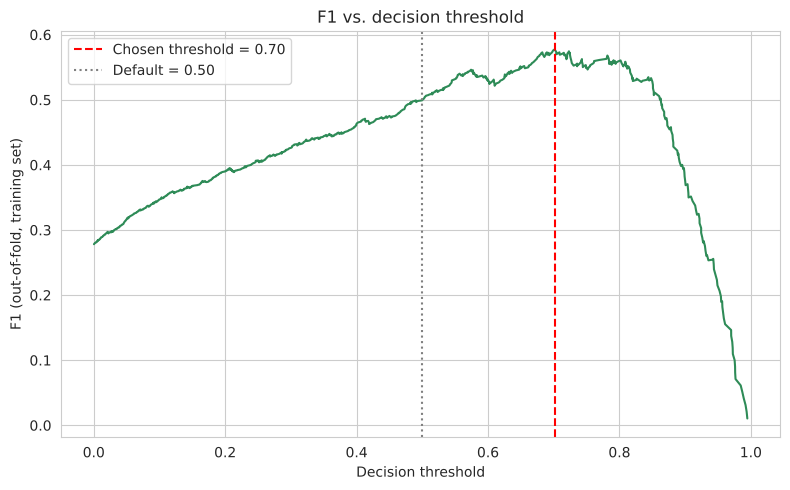

,Threshold,Accuracy,Precision,Recall,F1,TP,FP,FN,TN
Default (0.5),0.500,0.735,0.322,0.596,0.418,28,59,19,188
Tuned (from training CV),0.701,0.854,0.550,0.468,0.506,22,18,25,229


In [21]:
oof_proba = cross_val_predict(final_pipe, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

prec, rec, thr = precision_recall_curve(y_train, oof_proba)
f1_curve = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
best_threshold = float(thr[np.argmax(f1_curve)])

plt.figure(figsize=(8, 5))
plt.plot(thr, f1_curve, color="seagreen")
plt.axvline(best_threshold, color="red", linestyle="--", label=f"Chosen threshold = {best_threshold:.2f}")
plt.axvline(0.5, color="gray", linestyle=":", label="Default = 0.50")
plt.xlabel("Decision threshold")
plt.ylabel("F1 (out-of-fold, training set)")
plt.title("F1 vs. decision threshold")
plt.legend()
plt.tight_layout()
plt.show()


def threshold_metrics(threshold):
    pred = (y_proba_final >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {
        "Threshold": round(threshold, 3),
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
    }


threshold_df = pd.DataFrame(
    [threshold_metrics(0.5), threshold_metrics(best_threshold)],
    index=["Default (0.5)", "Tuned (from training CV)"],
).round(3)
threshold_df

### 8.2 Confusion matrix and classification report
Using the tuned threshold.

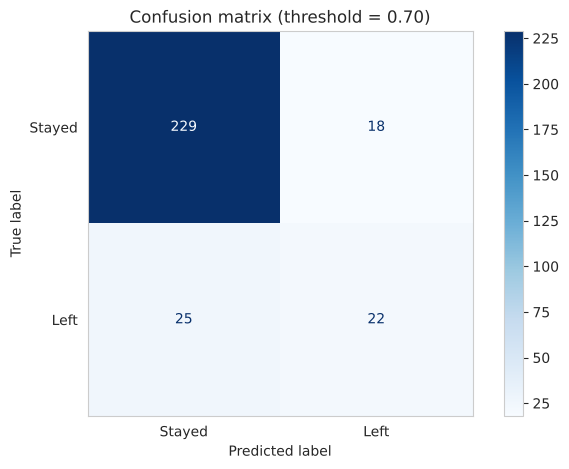

              precision    recall  f1-score   support

      Stayed      0.902     0.927     0.914       247
        Left      0.550     0.468     0.506        47

    accuracy                          0.854       294
   macro avg      0.726     0.698     0.710       294
weighted avg      0.845     0.854     0.849       294



In [22]:
y_pred_final = (y_proba_final >= best_threshold).astype(int)

disp = ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_final, display_labels=["Stayed", "Left"], cmap="Blues"
)
disp.ax_.grid(False)
plt.title(f"Confusion matrix (threshold = {best_threshold:.2f})")
plt.show()

print(classification_report(y_test, y_pred_final, target_names=["Stayed", "Left"], digits=3))

### 8.3 ROC and Precision-Recall curves

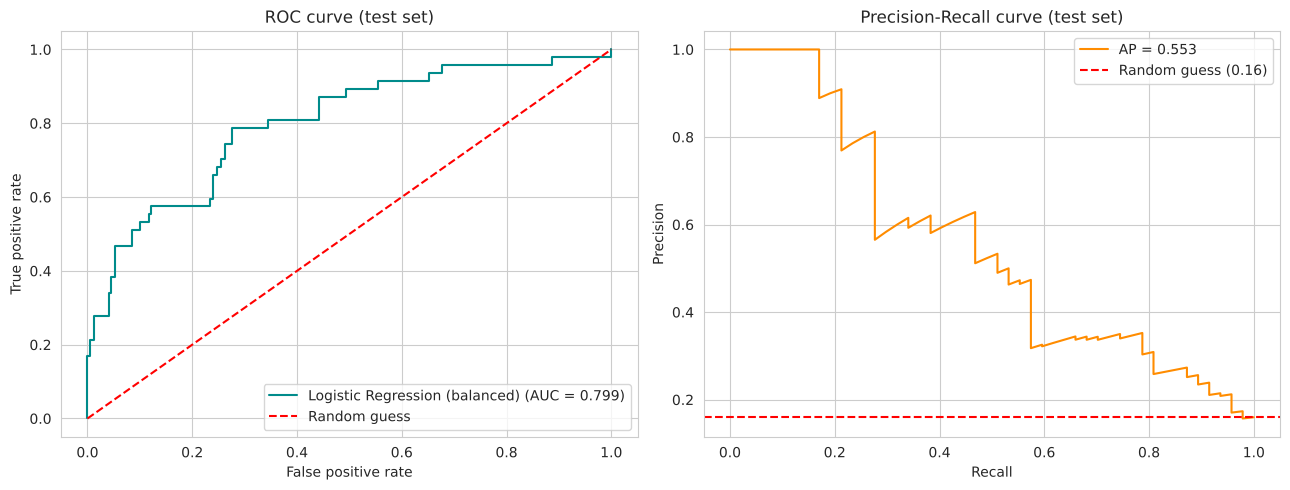

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

fpr, tpr, _ = roc_curve(y_test, y_proba_final)
axes[0].plot(fpr, tpr, color="darkcyan", label=f"{best_model_name} (AUC = {roc_auc_score(y_test, y_proba_final):.3f})")
axes[0].plot([0, 1], [0, 1], "r--", label="Random guess")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate")
axes[0].set_title("ROC curve (test set)")
axes[0].legend()

p, r, _ = precision_recall_curve(y_test, y_proba_final)
axes[1].plot(r, p, color="darkorange", label=f"AP = {average_precision_score(y_test, y_proba_final):.3f}")
axes[1].axhline(y_test.mean(), color="red", linestyle="--", label=f"Random guess ({y_test.mean():.2f})")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall curve (test set)")
axes[1].legend()

plt.tight_layout()
plt.show()

### 8.4 How certain is the test score?
The test set contains only a few dozen leavers, so a single AUC value is noisy. A bootstrap over the test set gives a rough 95% interval.

In [24]:
rng = np.random.default_rng(RANDOM_STATE)
y_arr = y_test.to_numpy()
boot_aucs = []
for _ in range(1000):
    idx = rng.integers(0, len(y_arr), len(y_arr))
    if y_arr[idx].min() == y_arr[idx].max():
        continue
    boot_aucs.append(roc_auc_score(y_arr[idx], y_proba_final[idx]))

ci_low, ci_high = np.percentile(boot_aucs, [2.5, 97.5])
print(f"Test ROC AUC = {roc_auc_score(y_test, y_proba_final):.3f}  (95% bootstrap CI: {ci_low:.3f} - {ci_high:.3f})")

Test ROC AUC = 0.799  (95% bootstrap CI: 0.720 - 0.872)


### 8.5 Actual vs. Predicted: risk tiers
Employees in the test set are split into three equal-sized risk tiers by predicted probability. If the model is useful, the attrition rate should rise clearly from Low to High.

In [25]:
test_results = pd.DataFrame({
    "Actual": y_test.values,
    "Probability": y_proba_final.round(3),
    "Predicted": y_pred_final,
}, index=y_test.index)
test_results["Risk tier"] = pd.qcut(test_results["Probability"], q=3, labels=["Low", "Medium", "High"])

tier_table = (
    test_results.groupby("Risk tier", observed=True)
    .agg(Employees=("Actual", "size"), Left=("Actual", "sum"), AttritionRate=("Actual", "mean"))
)
tier_table["Share of all leavers"] = tier_table["Left"] / tier_table["Left"].sum()
tier_table.round(3)

,Employees,Left,AttritionRate,Share of all leavers
Risk tier,,,,
Low,98,4,0.041,0.085
Medium,98,10,0.102,0.213
High,98,33,0.337,0.702


In [26]:
# The 10 employees the model considers highest risk
test_results.sort_values("Probability", ascending=False).head(10)

,Actual,Probability,Predicted,Risk tier
357,1,0.993,1,High
911,1,0.992,1,High
688,1,0.977,1,High
946,1,0.961,1,High
132,1,0.949,1,High
762,1,0.946,1,High
1021,1,0.943,1,High
514,1,0.931,1,High
301,0,0.930,1,High
36,1,0.894,1,High


## 9. Feature Importance

### 9.1 Permutation importance (final model)
Permutation importance works for any model: it measures how much the test ROC AUC drops when one original input column is shuffled. Because the pipeline takes the raw columns, importance is reported per original feature rather than per one-hot column.

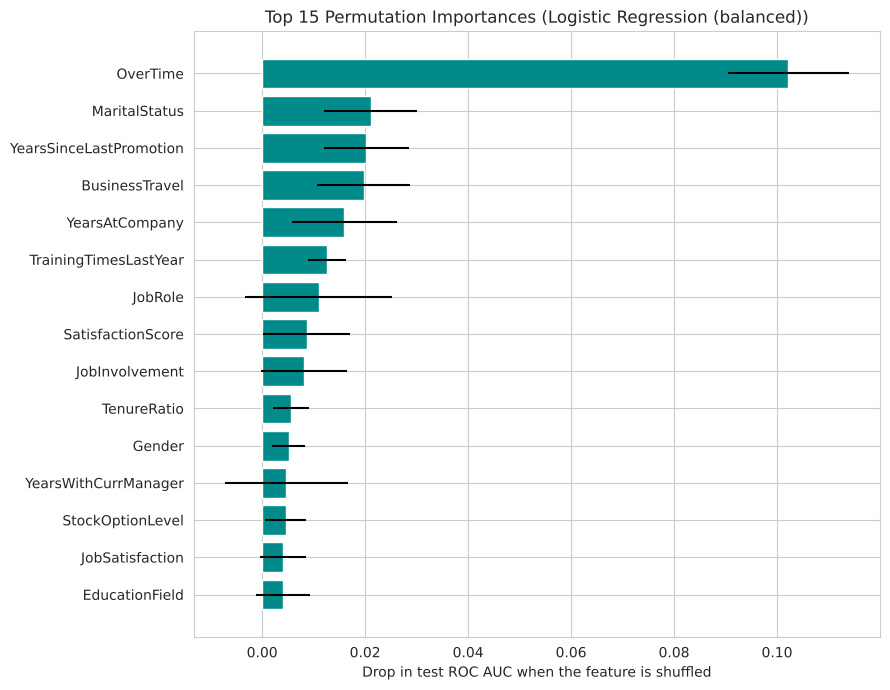

In [27]:
perm = permutation_importance(
    final_pipe, X_test, y_test, scoring="roc_auc",
    n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1,
)
perm_imp = pd.DataFrame({"mean": perm.importances_mean, "std": perm.importances_std}, index=X_test.columns)
top_perm = perm_imp.sort_values("mean", ascending=False).head(15)

plt.figure(figsize=(9, 7))
plt.barh(top_perm.index[::-1], top_perm["mean"][::-1], xerr=top_perm["std"][::-1], color="darkcyan")
plt.title(f"Top 15 Permutation Importances ({best_model_name})")
plt.xlabel("Drop in test ROC AUC when the feature is shuffled")
plt.tight_layout()
plt.show()

### 9.2 Direction of effect (Logistic Regression coefficients)
Permutation importance says *how much* a feature matters, not *which way* it pushes. The coefficients of the Logistic Regression model show direction: positive = higher attrition risk, negative = lower. Numeric features are standardized, so their coefficients are per one standard deviation; one-hot columns are per category. Correlated features (e.g. `JobLevel`, `MonthlyIncome`, `TotalWorkingYears`) share credit, so individual coefficients should be read as directions rather than exact effect sizes.

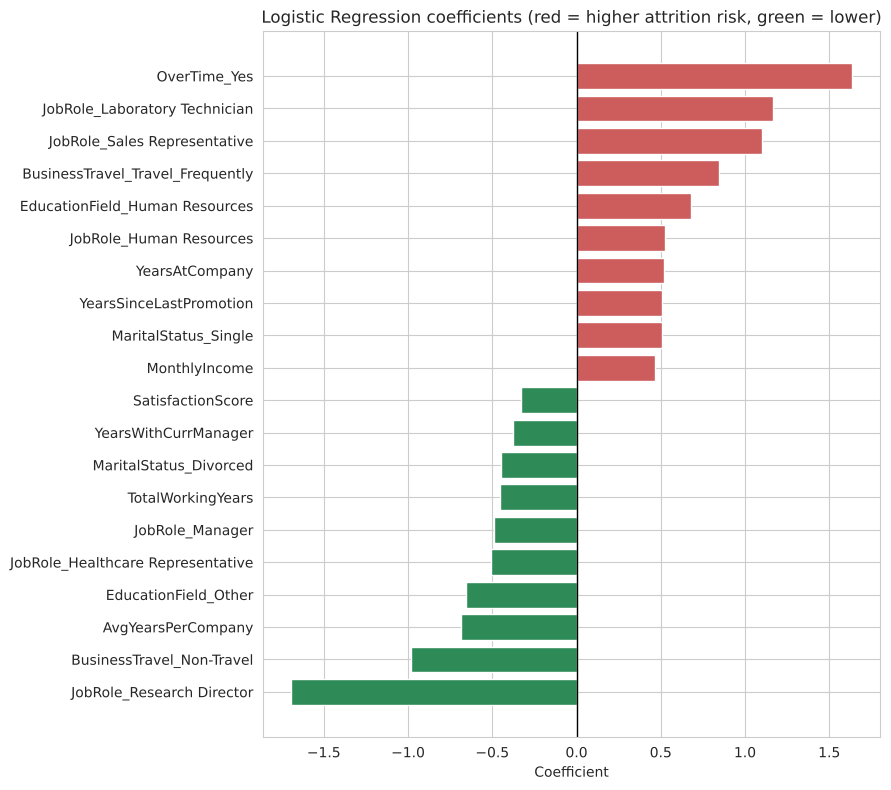

In [28]:
lr_pipe = models["Logistic Regression (balanced)"]
names = [n.split("__", 1)[1] for n in lr_pipe.named_steps["preprocess"].get_feature_names_out()]
coefs = pd.Series(lr_pipe.named_steps["model"].coef_[0], index=names).sort_values()

extremes = pd.concat([coefs.head(10), coefs.tail(10)])
colors = ["seagreen" if v < 0 else "indianred" for v in extremes.values]

plt.figure(figsize=(9, 8))
plt.barh(extremes.index, extremes.values, color=colors)
plt.axvline(0, color="black", linewidth=1)
plt.title("Logistic Regression coefficients (red = higher attrition risk, green = lower)")
plt.xlabel("Coefficient")
plt.tight_layout()
plt.show()

## 10. Conclusion

- **No data leakage, but a different trap.** Unlike `price_per_sqft` in the house-price project, no column here leaks the target (best single feature ≈ 0.66 AUC). The danger in this dataset is class imbalance: predicting "stays" for everyone is 84% accurate and useless, so models are judged on ROC AUC, PR AUC, recall and precision instead of accuracy.
- **Logistic Regression (balanced)** was selected on cross-validation (ROC AUC 0.830) and scored a test ROC AUC of 0.799 (95% bootstrap CI ≈ 0.72–0.87). That is a solid but not spectacular result, and the tree ensembles did not beat it.
- **The decision threshold matters.** At the default 0.5 the model catches 60% of leavers but only about 1 in 3 flags is correct (precision 0.32). A threshold of 0.70, tuned on training-set cross-validation only, gives precision 0.55 and recall 0.47 (F1 0.51). The right operating point depends on the cost of a missed leaver versus a wasted retention conversation.
- **The model is useful for ranking.** On the test set, the highest-risk third of employees had a 33.7% attrition rate versus 4.1% in the lowest-risk third, and contained 70% of all leavers.
- **Overtime is the dominant driver** by a wide margin (permutation importance ≈ 0.10 AUC versus about 0.02 or less for every other feature), followed by marital status, time since last promotion, business travel and tenure. Sales Representatives and Laboratory Technicians carry higher risk; Research Directors and Managers lower.
- **Caveats.**
  1. The test set contains only 47 leavers, hence the wide confidence interval.
  2. The data is fictional and a single snapshot.
  3. Coefficient signs of correlated features can mislead: `MonthlyIncome` and `YearsAtCompany` get *positive* coefficients even though leavers earn less and have shorter tenure in the EDA, because they overlap with `JobLevel`, `TotalWorkingYears` and each other. Read coefficients as rough directions, not causal effects.
  4. `Gender`, `Age` and `MaritalStatus` are protected-type attributes. Any real HR use would need a fairness and legal review first.
- **Next steps:** tune hyperparameters with `GridSearchCV`; try XGBoost / LightGBM; add SHAP values for per-employee explanations; calibrate the predicted probabilities; audit performance across gender and age groups.